# Этап 06. Построение динамической экономической сети

**Цель:** построить и сравнить правила формирования взвешенных графов экономического сходства муниципалитетов. Основные критерии — связность, разреженность и устойчивость сети во времени.

**Исходные данные:** 2016 муниципалитетов, шесть категорий расходов, 24 месяца (январь 2023 — декабрь 2024). Результаты этапа 05 показывают необходимость сравнения исходных долей и CLR-пространства. Годовые показатели и межгодовые изменения в расчёт рёбер не включаются.

**Результат этапа:** обоснованное правило построения сети и процедура сохранения 24 разреженных матриц для последующей кластеризации. Экономические рёбра характеризуют сходство, а не наблюдаемые потоки.

## 1. Математическая постановка

Для каждого месяца $t$ экономическая сеть имеет вид $G_t=(V,E_t,W_t,X_t)$, где $V$ — фиксированное множество муниципалитетов; $E_t$ — неориентированные рёбра сходства; $W_t$ — их веса; $X_t$ — матрица месячных атрибутов.

При временном окне $L$, заканчивающемся в $t$,

$$
X_t^{(L)}=[f(x_{t-L+1}),\ldots,f(x_t)],\qquad f\in\{\mathrm{raw},\mathrm{CLR}\}.
$$

Евклидово расстояние задаётся формулой

$$
d_t(i,j)=\sqrt{\sum_{r=1}^{6L}(X_{t,ir}-X_{t,jr})^2}.
$$

Для $L=1$ при $f=\mathrm{raw}$ оно характеризует различия самих долей расходов; при $f=\mathrm{CLR}$ — различия логарифмических отношений категорий (расстояние Эйчисона). CLR определяется как

$$
\operatorname{clr}(x)_p=\ln x_p-\frac16\sum_{q=1}^6\ln x_q.
$$

Преобразование применяется к положительным композициям. При нулевых долях численная процедура явно задаётся параметром `zero_floor`; произвольная скрытая импутация недопустима. Альтернативная метрика для того же CLR-пространства:

$$
d_{\cos}(i,j)=1-\frac{X_i^\mathsf{T}X_j}{\|X_i\|_2\|X_j\|_2}.
$$

При нулевой норме CLR-вектора косинусная метрика не определена. Временные окна используют только наблюдения не позднее $t$.

## 2. Правила формирования рёбер и весов

Пусть $N_k(i)$ — множество $k$ ближайших соседей вершины $i$ (без самой вершины). Сравниваются два способа симметризации:

$$
\{i,j\}\in E_t^{\cup}\iff j\in N_k(i)\ \lor\ i\in N_k(j),
$$

$$
\{i,j\}\in E_t^{\cap}\iff j\in N_k(i)\ \land\ i\in N_k(j).
$$

**Union kNN** включает связь при соседстве хотя бы в одном направлении; **mutual kNN** — только при взаимном соседстве. Третий вариант — union kNN с косинусной вместо евклидовой метрики. Равенства расстояний разрешаются детерминированно по исходному порядку муниципалитетов.

Вес любого существующего ребра определяется как

$$
w_{ij,t}=\exp\!\left[-\left(\frac{d_t(i,j)}{\sigma_t}\right)^2\right],\qquad
\sigma_t=\operatorname{median}\{d_t(i,j)>0:\{i,j\}\in E_t\}.
$$

Если положительных расстояний нет, принимается $\sigma_t=1$. Масштаб $\sigma_t$ рассчитывается для каждого месяца отдельно: это обеспечивает относительную нормировку весов, но ограничивает их прямую межмесячную сопоставимость. Вес ребра не является величиной денежного или транспортного потока.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.feature_analysis import SHARES, parse_dynamic_columns, composition_diagnostics
from src.graph_construction import (feature_at,build_graph,graph_metrics,edge_jaccard,experiment,save_sequence)
cfg=json.loads((ROOT/'configs'/'graph_experiment.json').read_text(encoding='utf-8'))
path=ROOT/cfg['feature_path']
assert path.is_file(),f'Нет файла: {path}'
X_dynamic=pd.read_parquet(path)
assert len(X_dynamic)==2016 and X_dynamic.index.is_unique and not X_dynamic.index.hasnans
mapping=parse_dynamic_columns(X_dynamic)
months=[str(p) for p in sorted({p for p,_ in mapping})]
print('Данные:',path.relative_to(ROOT),'форма:',X_dynamic.shape,'месяцы:',months[0],months[-1])
print('Шесть признаков:',SHARES)
assert (composition_diagnostics(X_dynamic,mapping)[['missing_cells','negative_cells','nonfinite_cells']]==0).all().all()
assert composition_diagnostics(X_dynamic,mapping)['max_sum_error'].max()<1e-6
assert cfg['selection']['method'] in (None, 'union', 'mutual', 'cosine')
display(pd.DataFrame({'municipality':X_dynamic.index.astype(str)[:5]}))

Данные: outputs/bdmo_v3/features/X_consumer_24m.parquet форма: (2016, 144) месяцы: 2023-01 2024-12
Шесть признаков: ('share_food', 'share_health', 'share_marketplace', 'share_dining', 'share_transport', 'share_other')


,municipality
0,1
1,2
2,3
3,4
4,5


## 3. Загрузка данных и контроль построения

Загружаем подготовленную матрицу, проверяем порядок 2016 муниципалитетов и структуру месяцев. На одном месяце контролируем симметричность графа, отсутствие петель, отношение между mutual и union и численный диапазон весов.

In [2]:
probe=feature_at(X_dynamic,mapping,months[-1],1,'raw')
probe_rows=[]
for method in cfg['methods']:
    a,meta=build_graph(probe,method,10)
    assert a.shape==(2016,2016) and (a-a.T).nnz==0 and np.all(a.diagonal()==0)
    probe_rows.append({'method':method,**graph_metrics(a),**meta})
display(pd.DataFrame(probe_rows).round(4))

,method,nodes,edges,density,components,giant_share,degree_mean,degree_p10,degree_p50,degree_p90,isolated_share,weight_p10,weight_p50,weight_p90,sigma,zero_distance_edges,mode,k
0,union,2016,13274,0.0065,1,1.0000,13.1687,10.0,13.0,17.0,0.0000,0.0347,0.3679,0.6870,0.0149,0,union,10
1,mutual,2016,6886,0.0034,32,0.9802,6.8313,3.0,7.0,10.0,0.0134,0.0669,0.3679,0.6804,0.0125,0,mutual,10
2,cosine,2016,13249,0.0065,1,1.0000,13.1438,10.0,13.0,17.0,0.0000,0.0000,0.3691,0.8553,0.0003,0,union,10


## 4. Первичный сравнительный эксперимент

Для предварительного отбора исследуются четыре даты, пять значений $k\in\{5,10,15,20,30\}$, raw/CLR, методы union/mutual/cosine и окна 1/3 месяца. При $L=3$ первые два месяца не используются: будущие наблюдения не подставляются.

**Метрики:** число рёбер $|E_t|$, плотность $\rho_t=2|E_t|/[n(n-1)]$, число компонент, доля вершин в крупнейшей компоненте, степени и квантили весов. Связность оценивается по графу положительных рёбер без дополнительного порога.

In [3]:
# Полное сравнение по 24 месяцам занимает ощутимое время; сначала небольшой срез.
# Явно фиксируем месяцы: по одному из четырёх частей временного интервала.
sample_months=[months[i] for i in [5,11,17,23]]
print('Даты первичного среза:',sample_months)
small=experiment(X_dynamic,mapping,sample_months,cfg['methods'],cfg['k_values'],
                 cfg['window_lengths'],cfg['representations'],cfg['zero_floor'])
cols=['representation','window','method','k','edges','components','giant_share','degree_p50','weight_p50']
summary=small.groupby(['representation','window','method','k'],as_index=False).agg(
    edges=('edges','median'),components=('components','median'),
    giant_share=('giant_share','median'),degree_p50=('degree_p50','median'),
    weight_p50=('weight_p50','median'))
display(summary.loc[:,cols].round(3).head(20))
print('Число сравниваемых комбинаций:',len(summary),'строк метрик:',len(small))

Даты первичного среза: ['2023-06', '2023-12', '2024-06', '2024-12']


,representation,window,method,k,edges,components,giant_share,degree_p50,weight_p50
0,clr,1,cosine,5,6772.5,2.0,1.000,7.0,0.370
1,clr,1,cosine,10,13410.0,2.0,1.000,13.0,0.369
2,clr,1,cosine,15,20109.0,2.0,1.000,20.0,0.369
3,clr,1,cosine,20,26799.5,1.0,1.000,26.5,0.369
4,clr,1,cosine,30,40284.5,1.0,1.000,40.0,0.368
5,clr,1,mutual,5,3071.5,148.0,0.885,3.0,0.368
6,clr,1,mutual,10,6294.5,33.0,0.980,6.0,0.368
7,clr,1,mutual,15,9479.0,18.5,0.988,10.0,0.368
8,clr,1,mutual,20,12660.0,14.5,0.992,13.0,0.368
9,clr,1,mutual,30,19117.0,7.0,0.997,20.0,0.368


Число сравниваемых комбинаций: 60 строк метрик: 240


## 5. Чувствительность структуры к числу соседей

Графики иллюстрируют компромисс между плотностью и связностью. Данные четырёх контрольных дат служат для первичного анализа, но сами по себе недостаточны для окончательного выбора параметров 24-месячной последовательности.

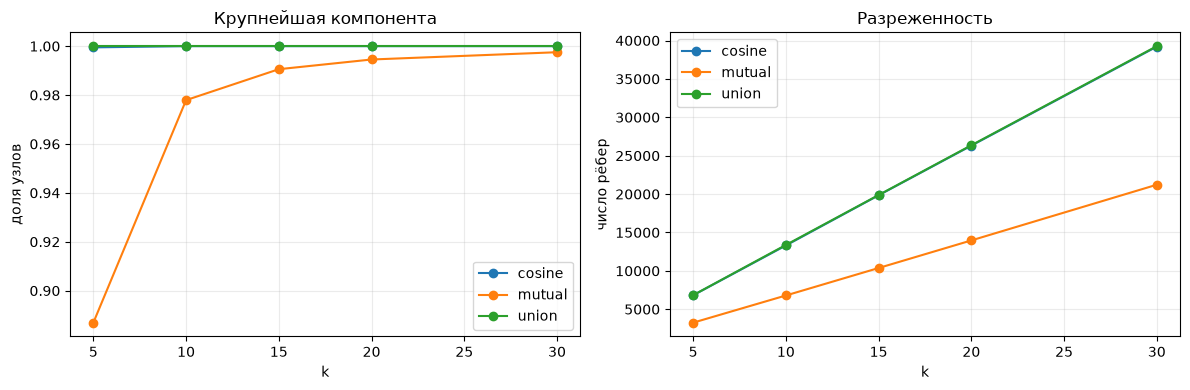

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
subset=summary.query('representation=="raw" and window==1')
for method,g in subset.groupby('method'):
    g=g.sort_values('k')
    axes[0].plot(g.k,g.giant_share,marker='o',label=method)
    axes[1].plot(g.k,g.edges,marker='o',label=method)
axes[0].set(title='Крупнейшая компонента',xlabel='k',ylabel='доля узлов')
axes[1].set(title='Разреженность',xlabel='k',ylabel='число рёбер')
for ax in axes:ax.grid(alpha=.25);ax.legend()
plt.tight_layout();plt.show()

## 6. Динамика трёх базовых сценариев

Первоначально сравниваются на всех 24 месяцах три сценария при $k=10$: raw/union, raw/mutual и CLR/union. Временная устойчивость определяется по соседним календарным месяцам:

$$
J_t=\frac{|E_t\cap E_{t-1}|}{|E_t\cup E_{t-1}|},\qquad t=2,\ldots,24.
$$

Индекс Жаккара оценивает совпадение **составов рёбер**, но не их весов. Высокое значение не доказывает экономическую содержательность сети.

,edges_median,components_median,giant_min,jaccard_median,sigma_min,sigma_max
scenario,,,,,,
clr/union/k=10,13888.5,1.0,1.000,0.266,0.164,0.187
raw/mutual/k=10,6700.0,30.0,0.975,0.157,0.013,0.014
raw/union/k=10,13460.0,1.0,1.000,0.196,0.015,0.017


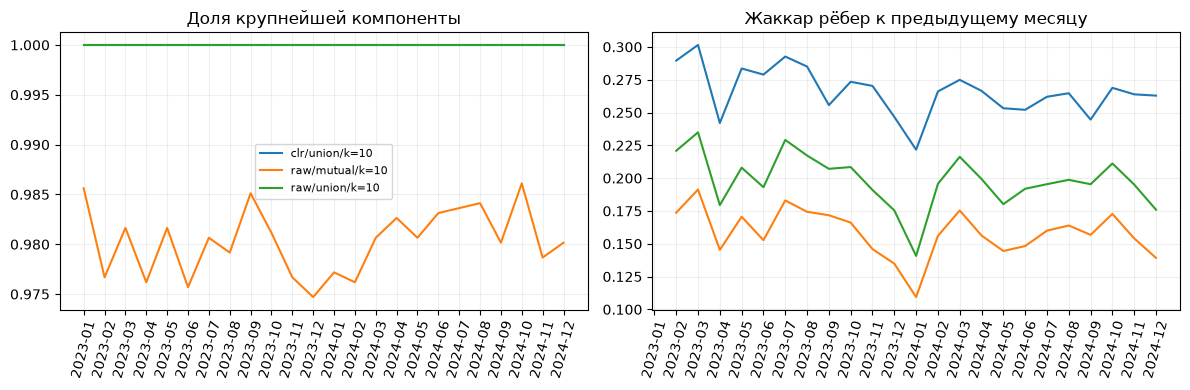

In [5]:
scenarios=[('raw','union',10),('raw','mutual',10),('clr','union',10)]
trend_parts=[]
for rep,method,k in scenarios:
    tmp=experiment(X_dynamic,mapping,months,[method],[k],[1],[rep],cfg['zero_floor'])
    tmp['scenario']=f'{rep}/{method}/k={k}'
    trend_parts.append(tmp)
trends=pd.concat(trend_parts,ignore_index=True)
display(trends.groupby('scenario').agg(
    edges_median=('edges','median'),components_median=('components','median'),
    giant_min=('giant_share','min'),jaccard_median=('jaccard_prev','median'),
    sigma_min=('sigma','min'),sigma_max=('sigma','max')).round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for scenario,g in trends.groupby('scenario'):
    axes[0].plot(g.month,g.giant_share,label=scenario)
    axes[1].plot(g.month,g.jaccard_prev,label=scenario)
for ax,title in zip(axes,['Доля крупнейшей компоненты','Жаккар рёбер к предыдущему месяцу']):
    ax.set_title(title);ax.tick_params(axis='x',rotation=75);ax.grid(alpha=.2)
axes[0].legend(fontsize=8);plt.tight_layout();plt.show()

## 7. Степени и веса: пример одного месяца

Распределения степеней и весов показываются для иллюстративного месячного графа. Эти графики не заменяют диагностику всех 24 месяцев; особенно важно учитывать очень слабые положительные веса, которые сохраняют формальную связность.

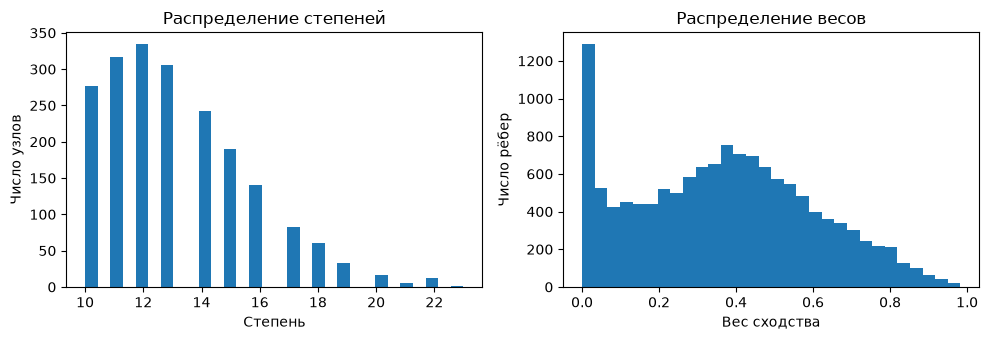

Месяц: 2024-12 sigma: 0.014923694277216577 диапазон весов: (np.float64(9.290112296255777e-33), np.float64(0.9826701845148333))


In [6]:
a,meta=build_graph(feature_at(X_dynamic,mapping,months[-1],1,'raw'),'union',10)
deg=np.diff(a.indptr)
from scipy.sparse import triu
w=triu(a,k=1).data
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].hist(deg,bins=30);axes[0].set(xlabel='Степень',ylabel='Число узлов',title='Распределение степеней')
axes[1].hist(w,bins=30);axes[1].set(xlabel='Вес сходства',ylabel='Число рёбер',title='Распределение весов')
plt.tight_layout();plt.show()
print('Месяц:',months[-1],'sigma:',meta['sigma'],'диапазон весов:',(w.min(),w.max()))

## 8. Полная проверка альтернатив на 24 месяцах

Для окончательной проверки построены **240 графов**: методы CLR/union (евклидово расстояние) и CLR/cosine (косинусное расстояние), $k\in\{5,10,15,20,30\}$, окно $L=1$, все 24 месяца. Остальные факторы фиксированы.

Сравниваются доля связных месяцев, минимальный размер крупнейшей компоненты, число рёбер, плотность, квантили степеней/весов и медианный/минимальный Жаккар между соседними месяцами. Графы этого проверочного эксперимента на диск не сохраняются.

In [7]:
k_check = [5, 10, 15, 20, 30]
assert len(months) == 24 and len(set(months)) == 24
assert set(k_check).issubset(set(cfg['k_values']))

full_check = experiment(
    X_dynamic, mapping, months,
    methods=['union', 'cosine'],
    ks=k_check,
    windows=[1],
    representations=['clr'],
    zero_floor=cfg['zero_floor'],
)
assert len(full_check) == 24 * 2 * len(k_check), full_check.shape
assert full_check.groupby(['method', 'k']).month.nunique().eq(24).all()
assert full_check.groupby(['method', 'k']).jaccard_prev.count().eq(23).all()
assert full_check.nodes.eq(len(X_dynamic)).all()

full_summary = (
    full_check.groupby(['method', 'k'], as_index=False)
    .agg(
        edges_median=('edges', 'median'),
        density_median=('density', 'median'),
        components_max=('components', 'max'),
        connected_months=('components', lambda s: int((s == 1).sum())),
        giant_share_min=('giant_share', 'min'),
        degree_p90_median=('degree_p90', 'median'),
        degree_p50_median=('degree_p50', 'median'),
        weight_p10_median=('weight_p10', 'median'),
        weight_p50_median=('weight_p50', 'median'),
        jaccard_median=('jaccard_prev', 'median'),
        jaccard_min=('jaccard_prev', 'min'),
    )
    .sort_values(['method', 'k'])
)
print('Проверено конфигураций:', full_summary.shape[0], '; графов:', len(full_check))
display(full_summary.round(4))

reference = full_summary.query('method == "union" and k == 10')
assert len(reference) == 1
print('Рабочий вариант CLR/union/k=10:')
display(reference.round(4))

Проверено конфигураций: 10 ; графов: 240


,method,k,edges_median,density_median,components_max,connected_months,giant_share_min,degree_p90_median,degree_p50_median,weight_p10_median,weight_p50_median,jaccard_median,jaccard_min
0,cosine,5,6754.5,0.0033,4,2,0.9980,9.0,7.0,0.0000,0.3698,0.1652,0.1249
1,cosine,10,13382.5,0.0066,3,2,0.9985,16.0,13.0,0.0000,0.3690,0.2182,0.1732
2,cosine,15,20049.0,0.0099,2,7,0.9995,24.0,20.0,0.0000,0.3690,0.2531,0.2037
3,cosine,20,26759.0,0.0132,2,15,0.9995,32.0,26.0,0.0000,0.3689,0.2810,0.2288
4,cosine,30,40222.0,0.0198,2,23,0.9995,47.0,40.0,0.0000,0.3684,0.3217,0.2672
5,union,5,7017.0,0.0035,1,24,1.0000,9.0,7.0,0.0289,0.3679,0.2122,0.1746
6,union,10,13888.5,0.0068,1,24,1.0000,17.0,13.0,0.0326,0.3679,0.2660,0.2217
7,union,15,20778.0,0.0102,1,24,1.0000,26.0,20.0,0.0343,0.3679,0.3002,0.2528
8,union,20,27693.5,0.0136,1,24,1.0000,34.0,27.0,0.0356,0.3679,0.3288,0.2793
9,union,30,41433.0,0.0204,1,24,1.0000,51.0,40.0,0.0390,0.3679,0.3699,0.3181


Рабочий вариант CLR/union/k=10:


,method,k,edges_median,density_median,components_max,connected_months,giant_share_min,degree_p90_median,degree_p50_median,weight_p10_median,weight_p50_median,jaccard_median,jaccard_min
6,union,10,13888.5,0.0068,1,24,1.0,17.0,13.0,0.0326,0.3679,0.266,0.2217


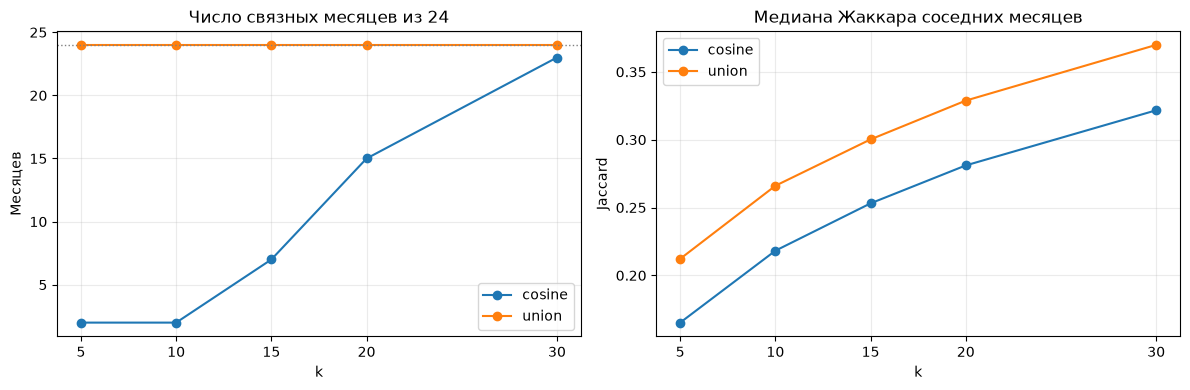

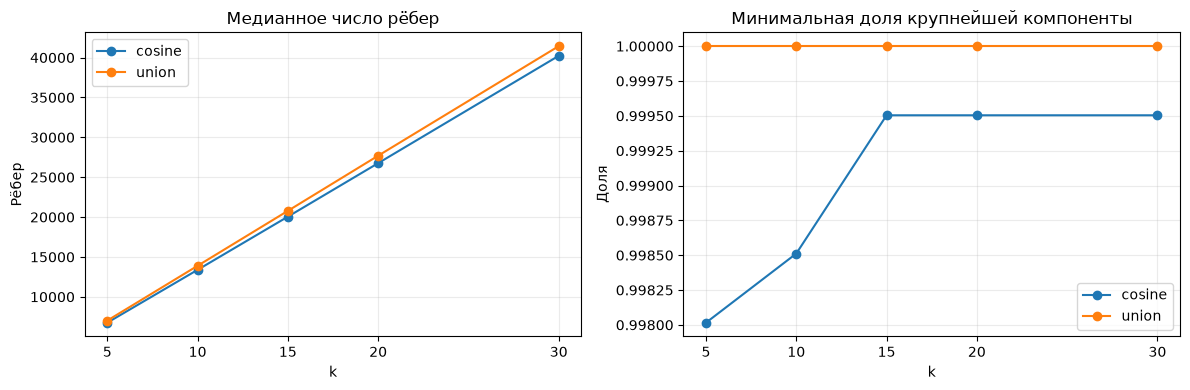

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method, group in full_summary.groupby('method'):
    group = group.sort_values('k')
    axes[0].plot(group['k'], group['connected_months'], marker='o', label=method)
    axes[1].plot(group['k'], group['jaccard_median'], marker='o', label=method)
axes[0].axhline(24, color='gray', linestyle=':', linewidth=1)
axes[0].set(title='Число связных месяцев из 24', xlabel='k', ylabel='Месяцев')
axes[1].set(title='Медиана Жаккара соседних месяцев', xlabel='k', ylabel='Jaccard')
for ax in axes:
    ax.set_xticks(k_check)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method, group in full_summary.groupby('method'):
    group = group.sort_values('k')
    axes[0].plot(group['k'], group['edges_median'], marker='o', label=method)
    axes[1].plot(group['k'], group['giant_share_min'], marker='o', label=method)
axes[0].set(title='Медианное число рёбер', xlabel='k', ylabel='Рёбер')
axes[1].set(title='Минимальная доля крупнейшей компоненты', xlabel='k', ylabel='Доля')
for ax in axes:
    ax.set_xticks(k_check)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## 9. Интерпретация результатов и выбор основной сети

### 9.1. Полнота расчётов

Все выполненные вычислительные ячейки содержат сохранённые результаты без исключений. Для основного сравнения получены **10 конфигураций × 24 месяца = 240 графов**; по каждой конфигурации вычислены 23 последовательных значения индекса Жаккара. Матрица признаков — **2016 × 144**, период — **2023-01—2024-12**, шесть категорий расходов.

### 9.2. Результаты полной проверки

| CLR-метрика / правило | $k$ | Связных месяцев / 24 | Медиана рёбер | Медиана Жаккара |
|---|---:|---:|---:|---:|
| Евклидова / union | 5 | 24 | 7 017 | 0,2122 |
| Евклидова / union | 10 | 24 | 13 888,5 | 0,2660 |
| Евклидова / union | 15 | 24 | 20 778 | 0,3002 |
| Евклидова / union | 20 | 24 | 27 693,5 | 0,3288 |
| Евклидова / union | 30 | 24 | 41 433 | 0,3699 |
| Косинусная / union | 5 | 2 | 6 754,5 | 0,1652 |
| Косинусная / union | 10 | 2 | 13 382,5 | 0,2182 |
| Косинусная / union | 15 | 7 | 20 049 | 0,2531 |
| Косинусная / union | 20 | 15 | 26 759 | 0,2810 |
| Косинусная / union | 30 | 23 | 40 222 | 0,3217 |

Евклидова метрика в CLR-пространстве обеспечила одну компоненту **для всех проверенных $k$ во все месяцы**. Косинусная метрика не обеспечила этого даже при $k=30$ (связны 23 месяца); при $k=10$ связны только два месяца. Для косинусной метрики медианный десятый процентиль весов в сводке округляется до `0,0000`, поэтому формальная топология не исчерпывает диагностику практической силы связей.

### 9.3. Выбор $k$ и компромисс между устойчивостью и разреженностью

При увеличении $k$ медианный Жаккар для CLR/union возрастает с **0,2122** до **0,3699**, но число рёбер увеличивается с **7 017** до **41 433** (почти в шесть раз). Рост перекрытия рёбер ожидаем при расширении соседств и не доказывает улучшение последующей кластеризации.

Выбор **$k=10$** сохраняется как **интерпретируемый рабочий компромисс**: сеть связна во всех месяцах, имеет медианную плотность **0,0068**, медиану **13 888,5** рёбер и Жаккар **0,2660** (минимум **0,2217**). При $k=5$ сеть примерно вдвое разреженнее, но устойчивость ниже; $k=15$ повышает Жаккар до **0,3002** ценой примерно 50%-ного увеличения числа рёбер. Это не строгий статистический оптимум, поскольку единый целевой критерий качества кластеризации пока не определён.

### 9.4. Сопоставление с диагностическими сценариями

При $k=10$ медиана Жаккара у raw/union составляет **0,196**, у raw/mutual — **0,157**, у CLR/union — **0,266**. Для raw/mutual медиана числа компонент составляет **30**. Это дополнительно поддерживает CLR/union как основное представление; однако окончательное подтверждение его пригодности будет связано с качеством кластеров на следующем этапе.

### 9.5. Экономическая интерпретация и ограничения

CLR/union соединяет муниципалитеты с близкими **соотношениями потребительских расходов**, а не обязательно с близкими объёмами потребления или наличием реальных межмуниципальных потоков. Рёбра и веса допускают временную изменчивость. Веса нормируются по месячной медиане расстояний $\sigma_t$, поэтому сопоставление их абсолютных уровней между месяцами требует осторожности.

Формальная связность не исключает присутствия чрезвычайно слабых рёбер. При дальнейшем анализе следует проверить чувствительность кластеров к малым весам и параметрам регуляризации. Нельзя считать рост Жаккара при большом $k$ независимым доказательством лучшей экономической типологии.

### 9.6. Решение и передача следующему этапу

**Основной вариант:** `representation="clr"`, `method="union"`, `k=10`, `window=1`, евклидово расстояние между CLR-композициями и гауссова весовая функция с помесячным $\sigma_t$. **Контрольный вариант для проверки чувствительности кластеризации:** CLR/union при $k=15$; он не требует смены геометрии, но изменяет насыщенность сети.

Для этапа 07 нужно сохранить **24 разреженные CSR-матрицы**, фиксированный порядок идентификаторов муниципалитетов, месяцы и параметры построения в манифесте. Ячейка сохранения ниже оставлена невыполненной: результат её выполнения следует проверить в вашей рабочей среде перед переходом к следующему этапу.

## 10. Сохранение выбранной последовательности

Ниже сохраняется **только выбранный вариант** CLR/union, $k=10$, окно 1 месяц. Ожидаемый результат — 24 файла `graph_YYYY-MM.npz` и один `manifest.json` в каталоге, заданном конфигурацией. Идентификаторы муниципалитетов должны соответствовать порядку строк `X_dynamic`.

In [9]:
selection = cfg['selection']
assert selection == {'method': 'union', 'representation': 'clr', 'window': 1, 'k': 10}, selection
manifest = save_sequence(
    X_dynamic, mapping, months, ROOT / cfg['output_directory'],
    method=selection['method'], k=selection['k'],
    representation=selection['representation'], window=selection['window'],
    zero_floor=cfg['zero_floor'],
)
print('Сохранено графов:', len(manifest['graphs']))
print('Каталог:', ROOT / cfg['output_directory'])
print('Число муниципалитетов:', len(manifest['node_ids']))


Сохранено графов: 24
Каталог: /Users/olgakan/vlad/hack/outputs/bdmo_v3/graphs_step06
Число муниципалитетов: 2016
